# Поиск разладок МЭГ методом прямоугольников: GA и PELT

Реализация геометрического подхода из **Benjamin Doerr, Paul Fischer, Astrid Hilbert, Carsten Witt — «Detecting structural breaks in time series via genetic algorithms»**. Статья опубликована онлайн в 2016 году, выпуск журнала — 2017. В библиографической записи имя третьего автора — **Astrid Hilbert**.

Задача из `../task.pdf` — автоматизировать разбиение магнитной энцефалограммы на участки между разладками тренда. Здесь исследуется предложенное пользователем покрытие последовательных участков прямоугольниками. Существующий модуль `utils/data_loading.py` используется для загрузки данных. Алгоритмы и вся визуализация находятся в **`src/rectangle_segmentation.py`**; в ноутбуке — параметры, вызовы и результаты.

Демонстрация использует локальный файл `excel-data/58voln_trial001_12.xlsx` и работает без скачивания MNE sample. Установка: `python -m pip install -r requirements.txt`. Выберите ядро Python с этими зависимостями.

## Общая целевая функция

Пусть $0=b_0<b_1<\dots<b_q=n$, а $k=q-1$ — число **внутренних** границ. Для каждого сегмента $[s,e)$ строится прямоугольник с высотой

$$h(s,e)=\max_{s\le i<e}y_i-\min_{s\le i<e}y_i.$$

Используется ширина **$e-s$ отсчётов**: наблюдение занимает свою временную ячейку. Поэтому площадь $A(s,e)=(e-s)h(s,e)$, а не SSE/дисперсия. Нормировка общая для всей записи:

$$C(s,e)=\frac{A(s,e)}{n(\max y-\min y)},\qquad
J(B)=\sum_{j=1}^{q}C(b_{j-1},b_j)+\beta k.$$

Для постоянного ряда $C=0$. Минимизируем $J$; меньший `penalty` ($\beta$) допускает больше сдвигов. При умножении амплитуды на ненулевую константу и добавлении смещения решение не меняется, что существенно для малых амплитуд МЭГ.

**Параметризация и адаптации.** Здесь явно выбран аддитивный штраф за внутреннюю границу. Взвешенная форма $(1-\alpha)A/A_0+\alpha k/K$ эквивалентна при $\beta=\alpha/((1-\alpha)K)$. В авторском Java-демо есть ограничение/насыщение штрафа по числу границ; здесь линейный штраф **не насыщается**, а жёсткого ограничения на число границ нет. Это позволяет сравнить GA и точный PELT на одной явно заданной задаче. Значения `penalty` из старого L2/RBF-метода сюда не переносятся.

Соглашение индексов совпадает с существующим кодом: `breakpoints` содержит конец каждого сегмента, включая `n`; `change_points` исключает `n`. Отсчёт с индексом `b` относится к **правому** сегменту. На графиках используется исходная амплитуда, а не нормированный ряд. При неравномерном времени оптимизация по-прежнему учитывает количество отсчётов, а не длительность в секундах.

## Два оптимизатора

**GA.** Разреженная хромосома хранит внутренние границы. В каждом раунде выполняется один оператор: равномерный кроссовер (`0.3`), одноточечный кроссовер (`0.3`) или мутация (`0.4`). Для мутации используются $p_m=\min(1,2\max(k,1)/n)$ и вероятность установить границу $p_b=0.6$; вероятность удалить выбранную границу $p_e=0.4$. Для пустой хромосомы используется $\max(k,1)$, чтобы из неё можно было выйти. Несовместимые с `min_size` границы удаляются случайным восстановлением допустимости. Отбор рулеткой использует положительный fitness $1/(1+J)$ — адаптацию к выбранной форме минимизации. Потомок заменяет худшего члена популяции, лучший найденный результат сохраняется отдельно. После независимых запусков проводится финальный поиск среди их чемпионов. PELT не используется для инициализации или улучшения GA.

В демонстрации — **8 популяций по 50 особей**, до 10 000 раундов, остановка после 800 раундов без улучшения. Для бюджета из [таблицы 3 статьи](https://link.springer.com/article/10.1007/s00500-016-2079-0/tables/3) задайте `n_restarts=100`. `max_initial_breaks=20` ограничивает только начальную популяцию. Результат GA зависит от `seed` и не обязан быть глобальным оптимумом.

**PELT.** Собственная реализация рекурсии

$$F(t)=\min_{0\le s\le t-m}\{F(s)+C(s,t)+\beta\},\qquad F(0)=-\beta,$$

где $m=$ `min_size`. Площадь удовлетворяет $C(a,b)+C(b,c)\le C(a,c)$, что позволяет применить PELT с константой отсечения $K_\mathrm{PELT}=0$. Если кандидат доминируется в $t$, его удаляют только начиная с $t+m$: раньше заменяющий его сегмент был бы слишком коротким. Проверяются **все** позиции, без `jump`; получаем глобальный минимум заданной функции при ограничении длины. В худшем случае время квадратичное.

Для запросов минимума/максимума используются статические sparse tables вместо дерева диапазонов авторов: подготовка и память $O(n\log n)$, запрос $O(1)$.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Работает при запуске Jupyter из корня репозитория или каталога experiments/.
PROJECT_ROOT = next(
    parent for parent in (Path.cwd(), *Path.cwd().parents)
    if (parent / "src").is_dir() and (parent / "utils" / "paths.py").is_file()
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from utils.paths import DATA_DIR, EXPERIMENTS_DIR

from utils import data_loading as data
from src import rectangle_segmentation as rect
from utils import rectangle_plots as rplot
%matplotlib inline

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
SEED = 42
GA_OPTIONS = dict(
    population_size=50, n_restarts=8, max_iterations=10000,
    patience=800, max_initial_breaks=20,
    p_uniform=0.3, p_one_point=0.3, p_insert=0.6, seed=SEED,
)


## 1. Синтетический ряд с известными границами

Три режима отличаются средним и разбросом. Истинные сдвиги находятся в индексах 120 и 240. Это проверка поведения алгоритма, а не замена реальных данных.

Истинные границы: [120, 240]
PELT: [120, 240] J = 0.322969
GA:   [120, 240] J = 0.322969


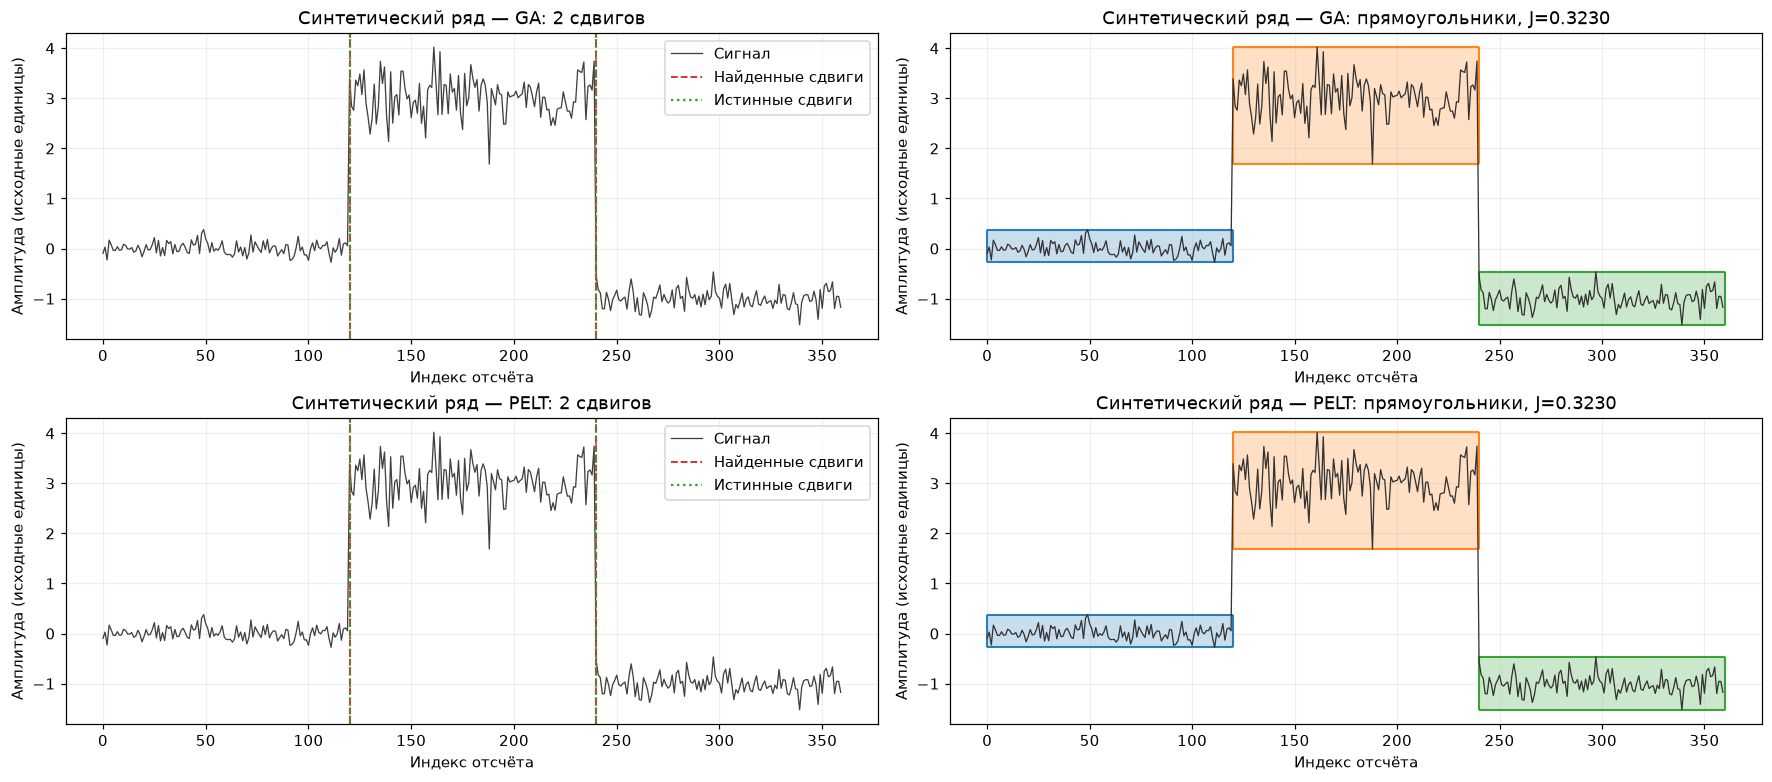

In [2]:
rng = np.random.default_rng(2026)
synthetic_signal = np.r_[
    rng.normal(0.0, 0.12, 120),
    rng.normal(3.0, 0.35, 120),
    rng.normal(-1.0, 0.18, 120),
]
synthetic = {"signal": synthetic_signal, "label": "Синтетический ряд"}
true_breaks = [120, 240]
synthetic_pelt = rect.segment_pelt(synthetic_signal, penalty=0.04, min_size=15)
synthetic_ga = rect.segment_genetic(
    synthetic_signal, penalty=0.04, min_size=15, **GA_OPTIONS
)
print("Истинные границы:", true_breaks)
print("PELT:", synthetic_pelt.change_points, "J =", round(synthetic_pelt.objective, 6))
print("GA:  ", synthetic_ga.change_points, "J =", round(synthetic_ga.objective, 6))
rplot.plot_comparison(synthetic, [synthetic_ga, synthetic_pelt], true_breakpoints=true_breaks)
plt.show()


Слева — найденные разладки и истинные границы; справа — прямоугольники, охватывающие все отсчёты каждого сегмента. Прямоугольники постоянных участков могут иметь нулевую высоту. Красная граница — начало следующего сегмента, а не последняя точка предыдущего.

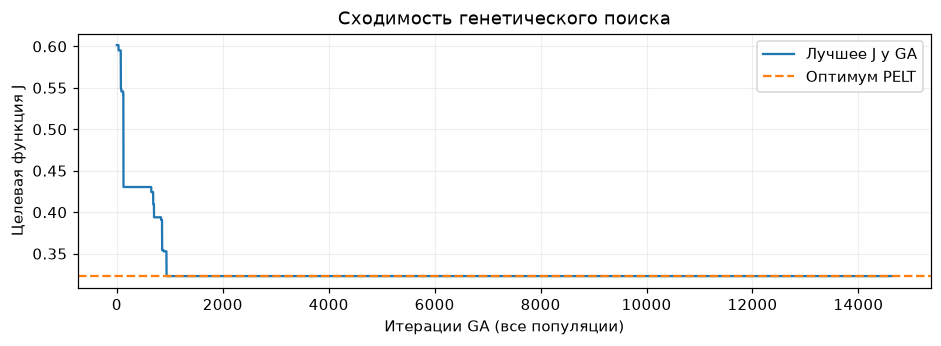

In [3]:
rplot.plot_convergence(synthetic_ga, synthetic_pelt)
plt.show()


## 2. МЭГ из локального Excel

Используется **существующая функция `data.load_xlsx_series`**. Выбираем три канала из одной записи; строка стимулов пропускается загрузчиком. Обрабатываем все 2001 отсчёт каждого выбранного канала без сглаживания и прореживания. `min_size=30` соответствует примерно 30 мс при частоте 1000 Гц.

Ручной разметки сдвигов в этом Excel нет. Поэтому ниже сравниваем целевую функцию и границы, а не точность относительно нейрофизиологической разметки.

In [4]:
DATA_FILE = DATA_DIR / "excel-data" / "58voln_trial001_12.xlsx"
CHANNELS = ["MEG0113", "MEG0112", "MEG0122"]
PENALTY = 0.02
MIN_SIZE = 30

series = data.load_xlsx_series(str(DATA_FILE), channel_names=CHANNELS)
for s in series:
    print(f"{s['channel_name']}: n={len(s['signal'])}, "
          f"fs={s['sfreq']:.1f} Гц, t={s['times'][0]:.3f}–{s['times'][-1]:.3f} с")

pelt_results = [
    rect.segment_pelt(s["signal"], penalty=PENALTY, min_size=MIN_SIZE) for s in series
]
ga_results = [
    rect.segment_genetic(s["signal"], penalty=PENALTY, min_size=MIN_SIZE, **GA_OPTIONS)
    for s in series
]


MEG0113: n=2001, fs=1000.0 Гц, t=0.000–2.000 с
MEG0112: n=2001, fs=1000.0 Гц, t=0.000–2.000 с
MEG0122: n=2001, fs=1000.0 Гц, t=0.000–2.000 с


In [5]:
table = [
    "| Канал | Метод | Сдвигов | Доля площади | Штраф βk | J | Время, с | Разрыв с PELT |",
    "|---|---|---:|---:|---:|---:|---:|---:|",
]
for s, ga, pelt in zip(series, ga_results, pelt_results):
    for result in [ga, pelt]:
        table.append(
            f"| {s['channel_name']} | {result.method} | {len(result.change_points)} "
            f"| {result.area_fraction:.5f} | {result.penalty * len(result.change_points):.5f} "
            f"| {result.objective:.5f} | {result.elapsed_seconds:.3f} "
            f"| {result.objective - pelt.objective:.5f} |"
        )
display(Markdown("\n".join(table)))


| Канал | Метод | Сдвигов | Доля площади | Штраф βk | J | Время, с | Разрыв с PELT |
|---|---|---:|---:|---:|---:|---:|---:|
| MEG0113 | GA | 4 | 0.80564 | 0.08000 | 0.88564 | 0.775 | 0.01141 |
| MEG0113 | PELT | 6 | 0.75424 | 0.12000 | 0.87424 | 0.050 | 0.00000 |
| MEG0112 | GA | 5 | 0.72985 | 0.10000 | 0.82985 | 0.628 | 0.00933 |
| MEG0112 | PELT | 7 | 0.68052 | 0.14000 | 0.82052 | 0.052 | 0.00000 |
| MEG0122 | GA | 6 | 0.73937 | 0.12000 | 0.85937 | 0.649 | 0.01106 |
| MEG0122 | PELT | 6 | 0.72831 | 0.12000 | 0.84831 | 0.061 | 0.00000 |

Чем меньше `J`, тем лучше покрытие с учётом штрафа. Разрыв GA с PELT показывает качество оптимизации **этого** критерия. Разное количество границ у методов допустимо: GA может остановиться на локальном решении. Время включает подготовку таблиц диапазонов, когда на вход передан исходный массив; замеры ориентировочные и зависят от компьютера.

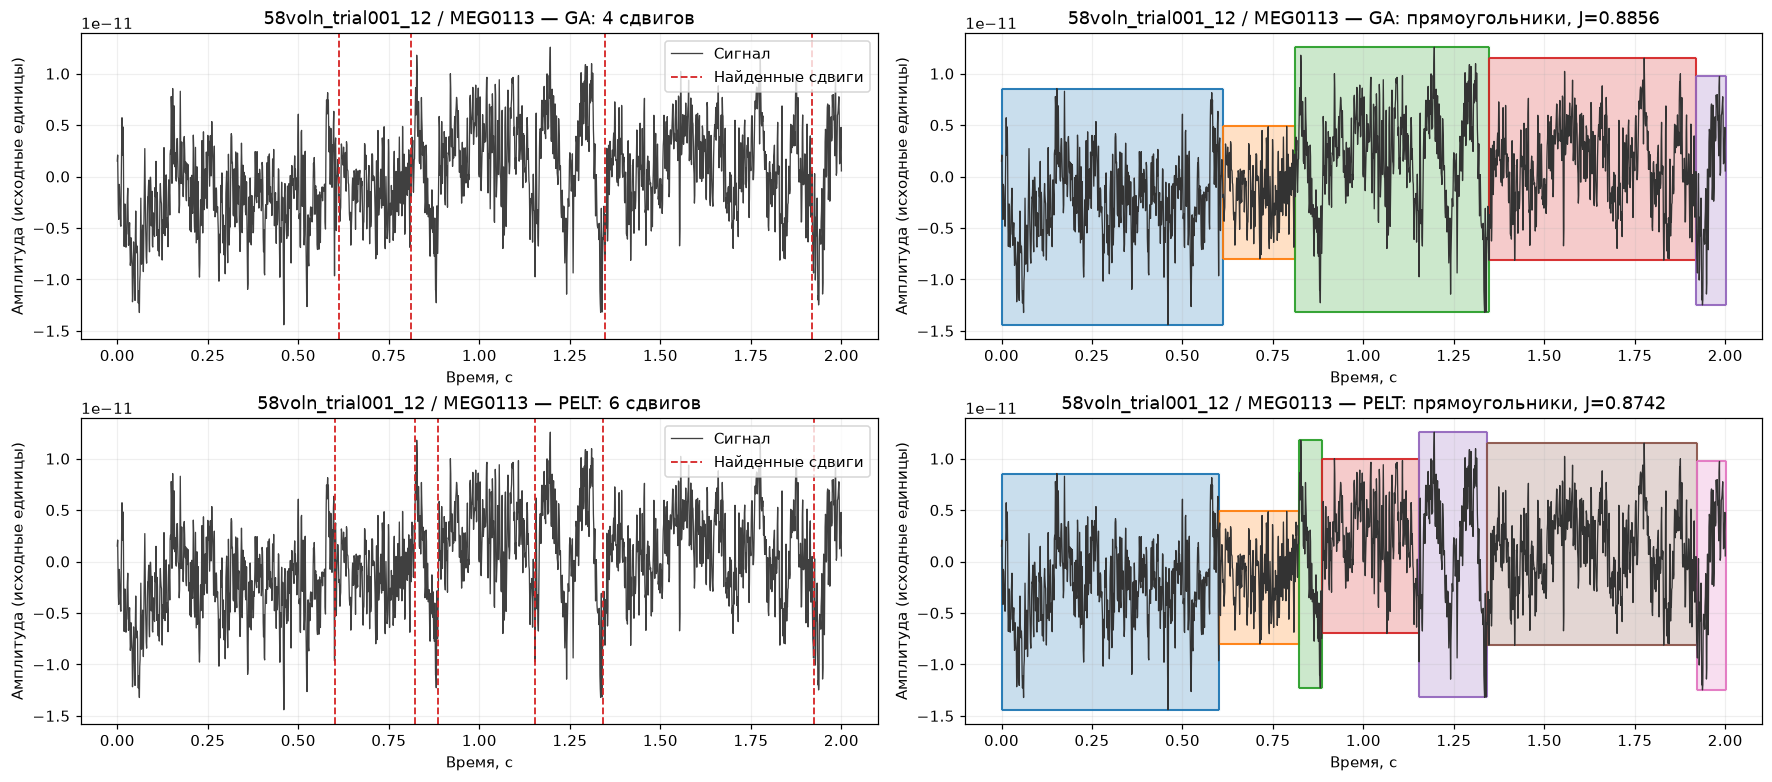

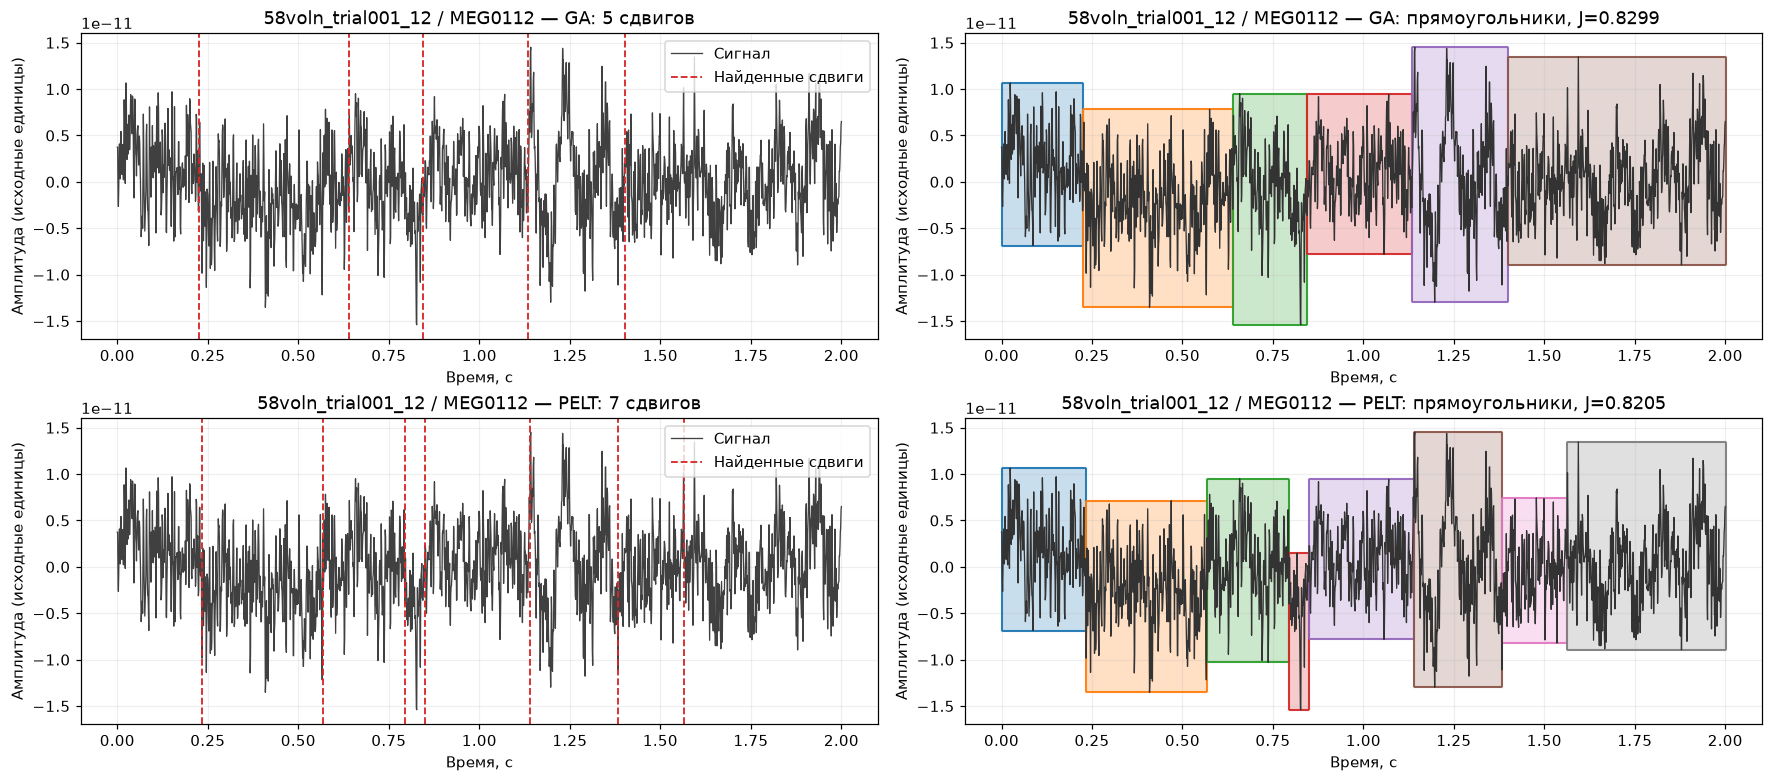

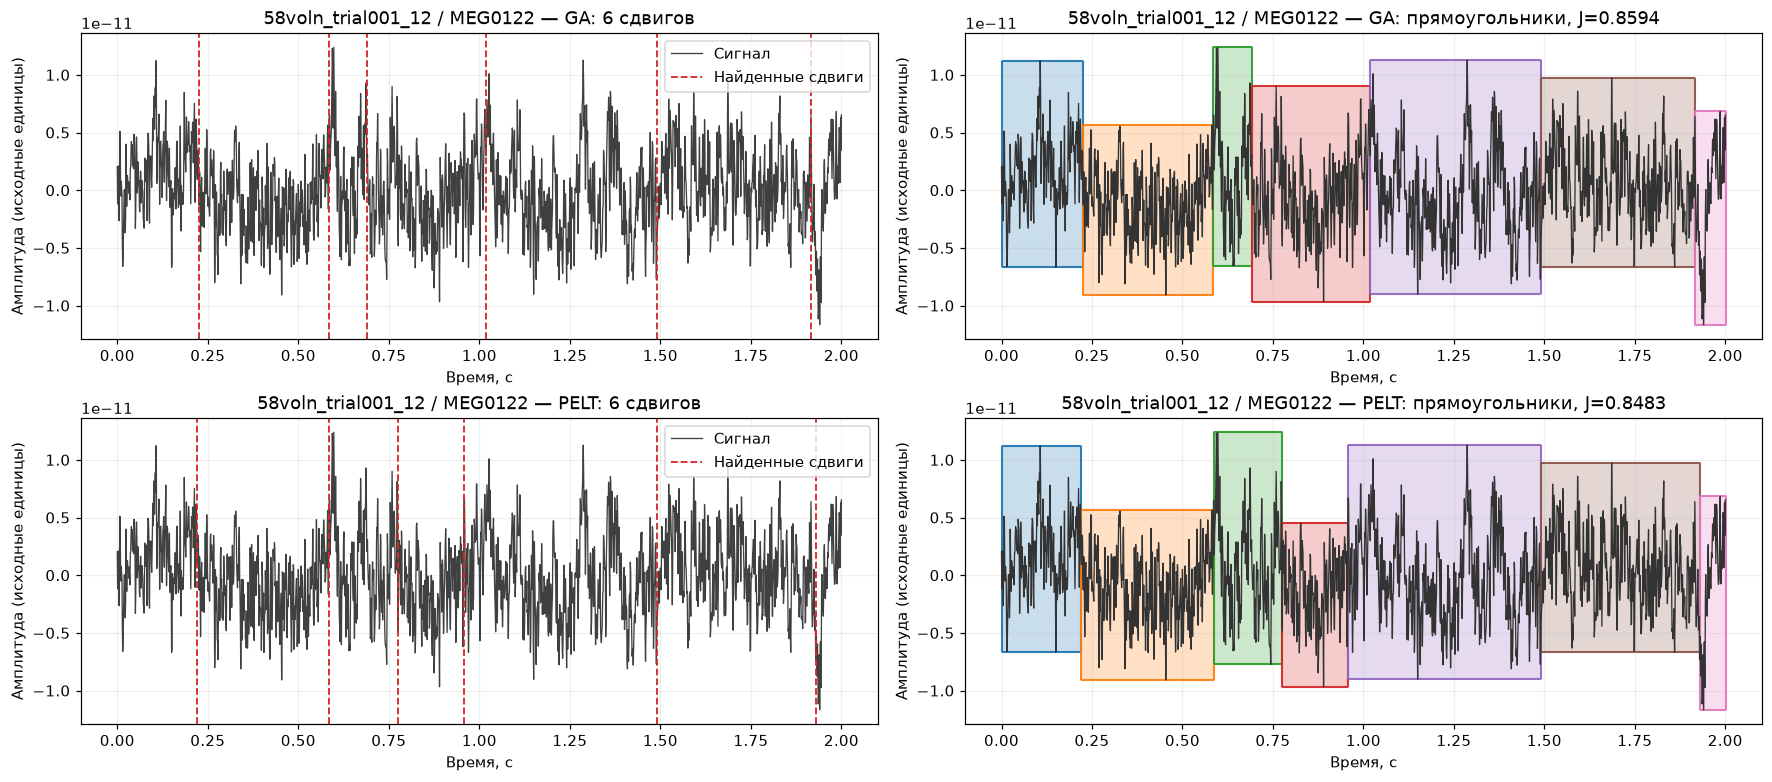

In [6]:
# Для каждого канала: строки GA/PELT, столбцы «сдвиги»/«прямоугольники».
for s, ga, pelt in zip(series, ga_results, pelt_results):
    rplot.plot_comparison(s, [ga, pelt])
    plt.show()


In [7]:
# Индексы границ и соответствующее время. n в список разладок не попадает.
for s, ga, pelt in zip(series, ga_results, pelt_results):
    print(s["channel_name"])
    for result in [ga, pelt]:
        print(f"  {result.method}: indices={result.change_points}")
        print("       seconds=", np.round(s["times"][result.change_points], 3).tolist())


MEG0113
  GA: indices=[613, 812, 1348, 1919]
       seconds= [0.613, 0.812, 1.348, 1.919]
  PELT: indices=[601, 823, 886, 1154, 1341, 1923]
       seconds= [0.601, 0.823, 0.886, 1.154, 1.341, 1.923]
MEG0112
  GA: indices=[226, 639, 845, 1134, 1401]
       seconds= [0.226, 0.639, 0.845, 1.134, 1.401]
  PELT: indices=[234, 567, 794, 850, 1141, 1384, 1564]
       seconds= [0.234, 0.567, 0.794, 0.85, 1.141, 1.384, 1.564]
MEG0122
  GA: indices=[226, 584, 691, 1019, 1491, 1916]
       seconds= [0.226, 0.584, 0.691, 1.019, 1.491, 1.916]
  PELT: indices=[219, 586, 775, 957, 1490, 1929]
       seconds= [0.219, 0.586, 0.775, 0.957, 1.49, 1.929]


## 3. Сходимость и влияние штрафа

PELT задаёт достижимый глобальный минимум. Кривая GA сохраняет лучший результат по мере всех запусков и финального поиска среди чемпионов. Параметры и ряд одинаковы у обоих оптимизаторов.

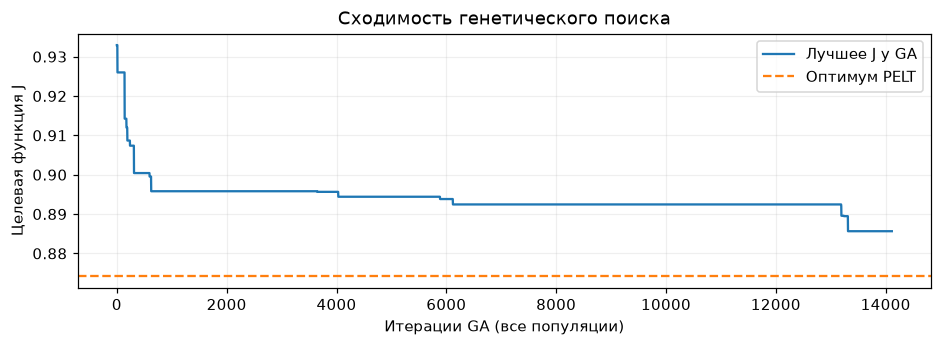

In [8]:
rplot.plot_convergence(ga_results[0], pelt_results[0])
plt.show()


In [9]:
penalties = [0.005, 0.01, 0.02, 0.04, 0.08]
sensitivity = [
    rect.segment_pelt(series[0]["signal"], penalty=beta, min_size=MIN_SIZE)
    for beta in penalties
]
display(Markdown(
    "| β | Сдвигов | Доля площади | J |\n|---:|---:|---:|---:|\n" +
    "\n".join(
        f"| {r.penalty:.3f} | {len(r.change_points)} | {r.area_fraction:.5f} | {r.objective:.5f} |"
        for r in sensitivity
    )
))


| β | Сдвигов | Доля площади | J |
|---:|---:|---:|---:|
| 0.005 | 31 | 0.48859 | 0.64359 |
| 0.010 | 19 | 0.57205 | 0.76205 |
| 0.020 | 6 | 0.75424 | 0.87424 |
| 0.040 | 2 | 0.87081 | 0.95081 |
| 0.080 | 1 | 0.91228 | 0.99228 |

Рост штрафа уменьшает количество границ у точного решения; значения `J` при разных штрафах относятся к разным задачам. Для других каналов и экспериментов параметр следует выбирать по требуемому масштабу сегментации или по доступной ручной разметке.

## Повторное использование

- Новый Excel того же формата: замените `DATA_FILE`, задайте `CHANNELS` и повторите запуск.
- Уже загруженные `mne.Epochs`: используйте `data.select_series(epochs, epoch_indices=[...], channel_names=[...])`, затем те же `rect.segment_*` и `rplot.plot_*`.
- Публичный MNE sample: существующий `data.load_sample_epochs()` загружает около 2.7 ГБ при первом вызове; для этого ноутбука он не нужен.
- Только один тип графика: `rplot.plot_change_points(series[0], pelt_results[0])` или `rplot.plot_rectangles(series[0], pelt_results[0])`. Обе функции возвращают `(figure, axes)`, поддерживают `ax=`; сохранить можно через `figure.savefig(...)`.
- Построенные сегменты доступны как `result.rectangles`: поля `start`, `end`, `lower`, `upper` в исходных единицах. Нормированная суммарная площадь — `result.area_fraction`.

Покрытие прямоугольниками реагирует на изменения диапазона амплитуд и чувствительно к выбросам. Геометрические границы не следует автоматически считать разладками производной или событиями когнитивного процесса. Для задачи выделения тренда из `task.pdf` нужна отдельная проверка по аннотированным сигналам; полиномиальный метод остаётся в прежнем `demo.ipynb`.

## Источники и проверки

- [Doerr et al., DOI 10.1007/s00500-016-2079-0](https://doi.org/10.1007/s00500-016-2079-0), [параметры GA, таблица 3](https://link.springer.com/article/10.1007/s00500-016-2079-0/tables/3).
- [Авторское Java-демо TSX](https://www2.imm.dtu.dk/~pafi/TSX/) — источник для сверки структуры GA и прямоугольного fitness; отличия параметризации описаны выше. Полный текст журнальной статьи находится за подпиской; доступны аннотация, таблицы, подписи к рисункам и авторская реализация.
- [Killick, Fearnhead, Eckley: Optimal Detection of Changepoints With a Linear Computational Cost](https://arxiv.org/abs/1101.1438) — PELT; применение к прямоугольной стоимости и отложенное отсечение реализованы здесь.
- `tests/test_rectangle_segmentation.py`: полный перебор разбиений коротких рядов, сравнение PELT с динамикой без отсечений, масштаб МЭГ, фиксированный seed GA, минимальная длина, проверка прямоугольников и координат графиков. Запуск из корня проекта: `python -m unittest discover -s tests -v`.